# Projet Détection de Spam

Lien du Dataset via Github : https://github.com/Djochrist/french-spam-text-dataset-v1.0/blob/main/data/messages.csv

## 1. Import du Dataset
J'ai importé le jeu de données avec la bibliothèque Pandas.

In [2]:
import pandas as pd
df = pd.read_csv("../data/messages.csv")

## 2. Taille du Dataset
Cette commande ci-dessous affichera le nombre de lignes et de colonnes au total, issu du jeu de données.

In [3]:
df.shape

(10000, 7)

## 3. Aperçu de mon Dataset
Ensuite, j'affiche les aperçus de mon jeu de données avec la commande ci dessous. On peut y retrouver les caractéristiques de mon jeu de données ci-joint.

In [4]:
df.head()

,id,text,label,domain,spam_category,split,template_group
0,synthetic-v11-00001,Alerte sécurité : Votre compte doit être vérif...,spam,sms,phishing,train,bf04c17ada2e2e41
1,synthetic-v11-00002,Vérification nécessaire : Une activité inhabit...,spam,sms,phishing,train,86ed40bfcde0e72a
2,synthetic-v11-00004,Vérification nécessaire : Votre compte doit êt...,spam,sms,phishing,train,5ef6f481165769ab
3,synthetic-v11-00006,Vérification nécessaire : Votre accès sera sus...,spam,sms,phishing,train,7dc7500004bbee1b
4,synthetic-v11-00007,Alerte sécurité : Votre compte doit être vérif...,spam,sms,phishing,train,bf04c17ada2e2e41


## 4.Types de colonnes 
Je vérifie le type de chaque colonne et le nombre de valeurs non nulles.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              10000 non-null  str  
 1   text            10000 non-null  str  
 2   label           10000 non-null  str  
 3   domain          10000 non-null  str  
 4   spam_category   10000 non-null  str  
 5   split           10000 non-null  str  
 6   template_group  10000 non-null  str  
dtypes: str(7)
memory usage: 2.7 MB


## 5. Filtrage sur les SMS
Le corpus contient plusieurs domaines. Je ne garde que les lignes où `domain` vaut `sms`, car c'est le sujet du projet.

In [6]:
print(df["domain"].value_counts())
sms = df[df["domain"] == "sms"].copy()
sms.shape

domain
sms      5000
email    5000
Name: count, dtype: int64


(5000, 7)

## 6. Répartition des classes et des partitions
Je compte les SMS légitimes et les spams, puis je regarde comment le corpus est découpé (`split`). Cela permet de repérer un éventuel déséquilibre entre classes.

In [7]:
print(sms["label"].value_counts())
print(sms["label"].value_counts(normalize=True).round(3))
print(sms["split"].value_counts())
print(sms.groupby(["split", "label"]).size())

label
spam          2500
legitimate    2500
Name: count, dtype: int64
label
spam          0.5
legitimate    0.5
Name: proportion, dtype: float64
split
train         3167
validation     917
test           916
Name: count, dtype: int64
split       label     
test        legitimate     500
            spam           416
train       legitimate    1500
            spam          1667
validation  legitimate     500
            spam           417
dtype: int64


## 7. Qualité des données
Je recherche les valeurs manquantes, les textes vides et les doublons.

In [15]:
print("Valeurs manquantes :\n", sms.isna().sum())
print("Textes vides :", (sms["text"].str.strip() == "").sum())
print("Doublons de texte :", sms["text"].duplicated().sum())

Valeurs manquantes :
 id                0
text              0
label             0
domain            0
spam_category     0
split             0
template_group    0
dtype: int64
Textes vides : 0
Doublons de texte : 0


## 8. Fuite possible entre partitions (`template_group`)
Plusieurs messages viennent du même modèle de texte. Je vérifie si un même groupe apparaît dans plusieurs partitions, car cela rendrait le test trop facile pour le modèle.

In [8]:
n_splits = sms.groupby("template_group")["split"].nunique()
print("Groupes présents dans plusieurs partitions :", (n_splits > 1).sum())
print("Nombre de groupes :", sms["template_group"].nunique())

Groupes présents dans plusieurs partitions : 0
Nombre de groupes : 52


## 9. Graphique : répartition des classes
Un graphique simple pour montrer le déséquilibre entre SMS légitimes et spams.

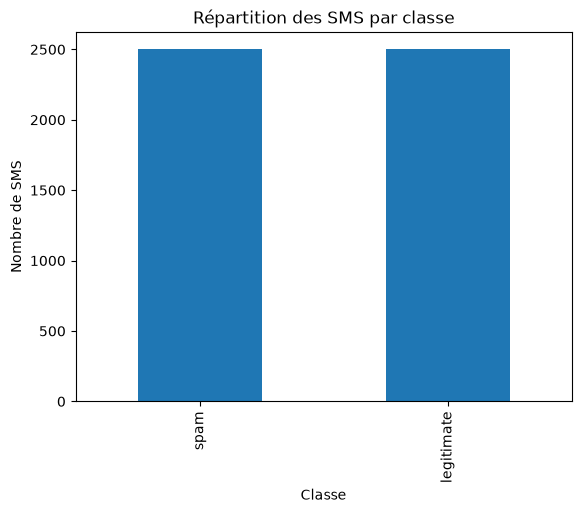

In [9]:
import matplotlib.pyplot as plt

sms["label"].value_counts().plot(kind="bar")
plt.title("Répartition des SMS par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de SMS")
plt.show()

## 10. Nettoyage
J'harmonise les labels (`spam` / `légitime`), je retire les textes vides et les doublons, en gardant les accents.

In [11]:
sms["label"] = sms["label"].replace({"legitimate": "légitime"})
sms = sms.dropna(subset=["text"])
sms = sms[sms["text"].str.strip() != ""]
sms = sms.drop_duplicates(subset="text")
print(sms.shape)
print(sms["label"].value_counts())

(5000, 7)
label
spam        2500
légitime    2500
Name: count, dtype: int64


## 11. Export des données propres
Je sauvegarde le jeu nettoyé et un fichier par partition, que l'équipe modèle utilisera pour l'entraînement et le test.

In [12]:
import os
os.makedirs("../data/processed", exist_ok=True)

cols = ["text", "label", "split"]
sms[cols].to_csv("../data/processed/sms_clean.csv", index=False)
for name, part in sms.groupby("split"):
    part[["text", "label"]].to_csv(f"../data/processed/{name}.csv", index=False)

## 12. Longueur des messages par classe
Je compare la longueur des SMS (en nombre de caractères) entre spams et SMS légitimes. Si les deux classes ont des longueurs très différentes, le modèle pourrait s'appuyer sur ce critère simple.

           count   mean   std    min    25%    50%    75%    max
label                                                           
légitime  2500.0  115.6   8.3  105.0  107.0  115.5  123.0  132.0
spam      2500.0  170.7  25.5  118.0  149.0  169.0  197.0  212.0


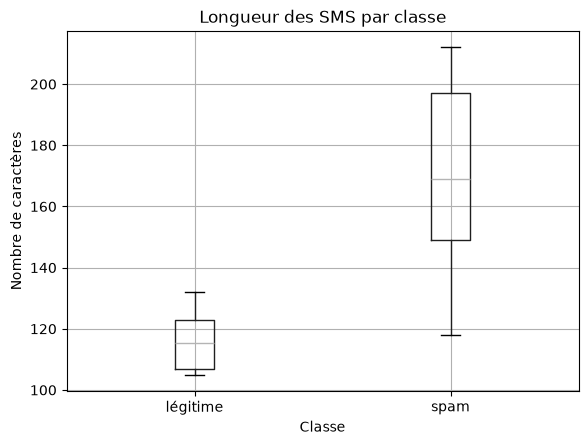

In [14]:
import matplotlib.pyplot as plt

longueurs = sms.assign(longueur=sms["text"].str.len())
print(longueurs.groupby("label")["longueur"].describe().round(1))

longueurs.boxplot(column="longueur", by="label")
plt.suptitle("")
plt.title("Longueur des SMS par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de caractères")
plt.show()

## 13. Vérification de l'export
Je relis les fichiers exportés pour confirmer qu'ils ont les bonnes tailles et les bonnes colonnes avant de les donner à l'équipe modèle.

In [ ]:
import pandas as pd

for nom in ["train", "validation", "test"]:
    d = pd.read_csv(f"../data/processed/{nom}.csv")
    print(nom, d.shape, list(d.columns))
    print(d["label"].value_counts().to_dict())